# 步驟 3：訓練迷你 Jev 模型
架構：**字元/2-gram → Embedding 查表 → 平均 → Dense → 兩個輸出頭（intent、color）**

在 VS Code 右上角選 kernel：`.venv (Python 3.12)`，然後一格一格按 ▶ 執行。

## 1. 載入資料

In [1]:
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from schema import INTENTS, COLORS
from tokenizer import tokenize, MAX_LEN, VOCAB_SIZE

plt.rcParams["font.family"] = ["Heiti TC", "Arial Unicode MS"]  # 讓圖表顯示中文

def load(path):
    rows = [json.loads(l) for l in open(path, encoding="utf-8")]
    X = np.array([tokenize(r["text"]) for r in rows], dtype=np.int32)
    y_intent = np.array([INTENTS.index(r["intent"]) for r in rows])
    y_color = np.array([COLORS.index(r["color"]) for r in rows])
    return rows, X, y_intent, y_color

train_rows, X_train, yi_train, yc_train = load("data/train.jsonl")
test_rows, X_test, yi_test, yc_test = load("data/test.jsonl")
print(f"訓練 {len(X_train)} 筆，考試 {len(X_test)} 筆")

訓練 3378 筆，考試 48 筆


## 2. 看一下 tokenizer 把句子變成什麼

In [2]:
s = "開紅燈"
print(s, "→", tokenize(s)[:8], "...（後面補 0）")
print("「開」「紅」「燈」是單字，後兩個是 2-gram「開紅」「紅燈」")

開紅燈 → [1420, 3334, 457, 2267, 1380, 0, 0, 0] ...（後面補 0）
「開」「紅」「燈」是單字，後兩個是 2-gram「開紅」「紅燈」


## 3. 建立模型
`MaskedMean`（定義在 `model.py`）：只平均真的字，**跳過補 0 的位置**，不然短句子的向量會被一堆 0 稀釋。

In [3]:
from model import MaskedMean

tf.keras.utils.set_random_seed(42)
inp = tf.keras.Input((MAX_LEN,), dtype="int32", name="tokens")
emb = tf.keras.layers.Embedding(VOCAB_SIZE, 32, name="embedding")(inp)    # ② 查表
x = MaskedMean(name="average")(emb, inp)                                  # ③ 平均
x = tf.keras.layers.Dense(64, activation="relu", name="dense")(x)         # ④ 組合特徵
intent = tf.keras.layers.Dense(len(INTENTS), name="intent")(x)            # ⑤ 輸出頭 1
color = tf.keras.layers.Dense(len(COLORS), name="color")(x)               # ⑤ 輸出頭 2
model = tf.keras.Model(inp, {"intent": intent, "color": color})

loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer="adam", loss={"intent": loss, "color": loss},
              metrics={"intent": "accuracy", "color": "accuracy"})
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, 32)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 32, 32)    │    131,104 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average             │ (None, 32)        │          0 │ embedding[0][0],  │
│ (MaskedMean)        │                   │            │ tokens[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,112 │ average[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ color (Dense)       │ (None, 7)         │        455 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ intent (Dense)      │ (None, 8)         │        520 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 134,191 (524.18 KB)

 Trainable params: 134,191 (524.18 KB)

 Non-trainable params: 0 (0.00 B)

## 4. 訓練
- **epoch**：把全部訓練資料看過一遍叫 1 個 epoch
- **loss** 越低越好；**accuracy** 越高越好
- **val_**：開頭的是「拿 10% 資料出來，不給模型學」的成績，用來看它是不是只是在背答案

In [4]:
history = model.fit(
    X_train, {"intent": yi_train, "color": yc_train},
    validation_split=0.1, epochs=20, batch_size=32, verbose=2)

Epoch 1/20


95/95 - 0s - 4ms/step - color_accuracy: 0.7937 - color_loss: 1.3096 - intent_accuracy: 0.3059 - intent_loss: 1.9769 - loss: 3.2864 - val_color_accuracy: 0.7959 - val_color_loss: 0.6675 - val_intent_accuracy: 0.3284 - val_intent_loss: 1.8425 - val_loss: 2.5068


Epoch 2/20


95/95 - 0s - 714us/step - color_accuracy: 0.8122 - color_loss: 0.5476 - intent_accuracy: 0.4286 - intent_loss: 1.5938 - loss: 2.1414 - val_color_accuracy: 0.8107 - val_color_loss: 0.4960 - val_intent_accuracy: 0.5207 - val_intent_loss: 1.2808 - val_loss: 1.7744


Epoch 3/20


95/95 - 0s - 703us/step - color_accuracy: 0.8309 - color_loss: 0.4400 - intent_accuracy: 0.6661 - intent_loss: 0.9757 - loss: 1.4157 - val_color_accuracy: 0.8107 - val_color_loss: 0.4434 - val_intent_accuracy: 0.8343 - val_intent_loss: 0.7217 - val_loss: 1.1636


... (30 outputs left out)

Epoch 19/20


95/95 - 0s - 681us/step - color_accuracy: 1.0000 - color_loss: 0.0076 - intent_accuracy: 1.0000 - intent_loss: 0.0068 - loss: 0.0144 - val_color_accuracy: 0.9911 - val_color_loss: 0.0344 - val_intent_accuracy: 0.9852 - val_intent_loss: 0.0450 - val_loss: 0.0820


Epoch 20/20


95/95 - 0s - 681us/step - color_accuracy: 1.0000 - color_loss: 0.0064 - intent_accuracy: 1.0000 - intent_loss: 0.0058 - loss: 0.0122 - val_color_accuracy: 0.9911 - val_color_loss: 0.0323 - val_intent_accuracy: 0.9852 - val_intent_loss: 0.0436 - val_loss: 0.0785


## 5. 畫學習曲線
兩條線都往下降、而且靠得很近 = 健康。如果 val 那條往上翹 = 開始死背（過擬合）。

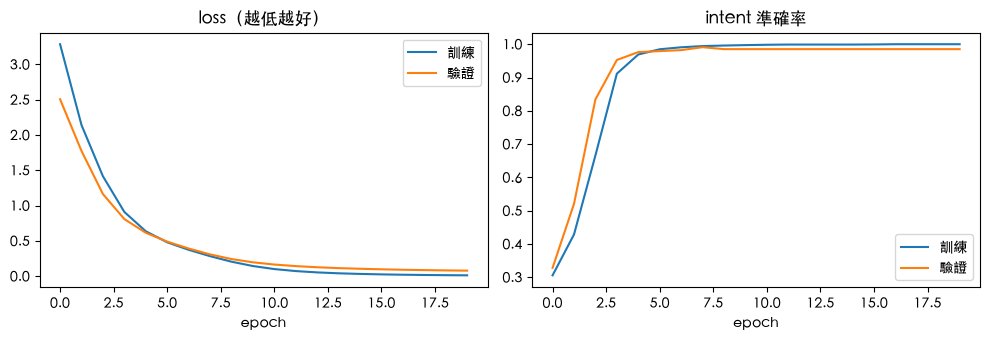

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="訓練")
ax[0].plot(history.history["val_loss"], label="驗證")
ax[0].set_title("loss（越低越好）"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["intent_accuracy"], label="訓練")
ax[1].plot(history.history["val_intent_accuracy"], label="驗證")
ax[1].set_title("intent 準確率"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. 考試
- **test.jsonl**：手寫、句型沒看過
- **generalize.jsonl**：舉一反三，關鍵字（大海、檸檬、照明…）完全沒出現在訓練資料裡

In [6]:
def exam(path):
    rows, X, yi, yc = load(path)
    out = model.predict(X, verbose=0)
    pi, pc = out["intent"].argmax(1), out["color"].argmax(1)
    p_intent = tf.nn.softmax(out["intent"]).numpy()
    print(f"【{path}】intent {(pi == yi).mean():.1%}｜color {(pc == yc).mean():.1%}｜全對 {((pi == yi) & (pc == yc)).mean():.1%}")
    for r, i, c, p in zip(rows, pi, pc, p_intent):
        if INTENTS[i] != r["intent"] or COLORS[c] != r["color"]:
            print(f"  ❌ {r['text']:<14} 正解 {r['intent']}/{r['color']:<7} 猜 {INTENTS[i]}/{COLORS[c]} (信心 {p.max():.2f})")
    print()
    return pi

pi = exam("data/test.jsonl")
exam("data/generalize.jsonl");

【data/test.jsonl】intent 87.5%｜color 97.9%｜全對 87.5%
  ❌ 關掉吧不用了         正解 OFF/NONE    猜 NONE/NONE (信心 0.94)
  ❌ 晚安關燈囉          正解 OFF/NONE    猜 NONE/NONE (信心 0.97)
  ❌ 閃藍色的燈          正解 BLINK/BLUE    猜 SET_COLOR/BLUE (信心 0.57)
  ❌ 這盞燈好亮          正解 NONE/NONE    猜 DIMMER/NONE (信心 0.66)
  ❌ 亮度這樣剛好         正解 NONE/NONE    猜 BRIGHTER/NONE (信心 0.70)
  ❌ 我要去洗澡          正解 NONE/NONE    猜 SET_COLOR/RED (信心 0.94)

【data/generalize.jsonl】intent 58.3%｜color 41.7%｜全對 16.7%
  ❌ 弄成大海的顏色        正解 SET_COLOR/BLUE    猜 SET_COLOR/YELLOW (信心 1.00)
  ❌ 換成天空的顏色        正解 SET_COLOR/BLUE    猜 SET_COLOR/YELLOW (信心 0.99)
  ❌ 燈光變成草莓色        正解 SET_COLOR/RED     猜 SET_COLOR/GREEN (信心 0.99)
  ❌ 像火焰一樣的顏色       正解 SET_COLOR/RED     猜 NONE/NONE (信心 0.96)
  ❌ 像檸檬一樣的顏色       正解 SET_COLOR/YELLOW  猜 NONE/NONE (信心 0.96)
  ❌ 換成葡萄的顏色        正解 SET_COLOR/PURPLE  猜 SET_COLOR/YELLOW (信心 1.00)
  ❌ 變成森林的顏色        正解 SET_COLOR/GREEN   猜 SET_COLOR/YELLOW (信心 1.00)
  ❌ 照明開啟           正解 ON/NONE    猜 NONE/NONE (信心 0.95)
  ❌ 光線太弱    

## 7. 混淆矩陣：哪一類被誤認成哪一類？
對角線 = 答對。對角線以外有數字 = 搞混了。

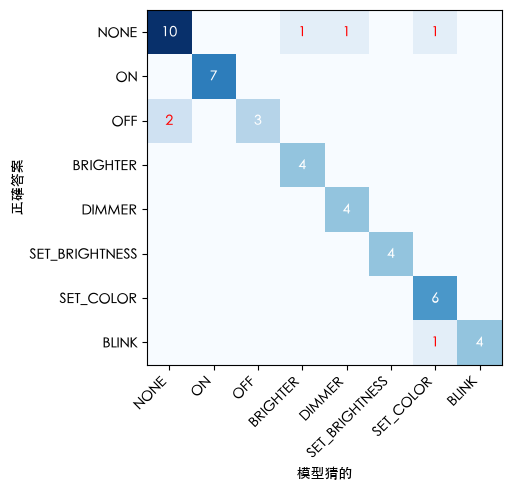

In [7]:
cm = tf.math.confusion_matrix(yi_test, pi, num_classes=len(INTENTS)).numpy()
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(INTENTS)), INTENTS, rotation=45, ha="right")
ax.set_yticks(range(len(INTENTS)), INTENTS)
ax.set_xlabel("模型猜的"); ax.set_ylabel("正確答案")
for i in range(len(INTENTS)):
    for j in range(len(INTENTS)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if i == j else "red")
plt.tight_layout(); plt.show()

## 8. 自己輸入句子試試看

In [8]:
def ask(text):
    o = model.predict(np.array([tokenize(text)]), verbose=0)
    p = tf.nn.softmax(o["intent"][0]).numpy()
    i, c = p.argmax(), o["color"][0].argmax()
    bars = "  ".join(f"{n} {v:.2f}" for n, v in zip(INTENTS, p) if v > 0.05)
    print(f"{text:<12} → {INTENTS[i]}/{COLORS[c]}  [{bars}]")

for s in ["開燈", "不要把燈打開", "千萬不要開燈", "拜託別換成藍色", "我沒說要閃",   # 否定 → NONE
          "不要亮了", "不夠亮", "不用那麼亮", "看不清楚"]:                       # 「不」的其他意思
    ask(s)

開燈           → ON/NONE  [ON 1.00]
不要把燈打開       → NONE/NONE  [NONE 1.00]
千萬不要開燈       → NONE/NONE  [NONE 0.98]
拜託別換成藍色      → NONE/BLUE  [NONE 0.69  SET_COLOR 0.31]
我沒說要閃        → NONE/NONE  [NONE 1.00]
不要亮了         → OFF/NONE  [NONE 0.14  OFF 0.86]
不夠亮          → BRIGHTER/NONE  [BRIGHTER 1.00]
不用那麼亮        → DIMMER/NONE  [DIMMER 0.99]
看不清楚         → BRIGHTER/NONE  [BRIGHTER 1.00]


## 9. 存檔（步驟 4 量化會用到）

In [9]:
model.save("jev_model.keras")
print("已存檔 → jev_model.keras")

已存檔 → jev_model.keras
